# Project Python Foundations: FoodHub Data Analysis

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [1]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [2]:
# Read the data to be analyzed
df = pd.read_csv('foodhub_order.csv')

In [3]:
# Present the first 5 rows of the dataset
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### 1. How large is the dataset?

In [4]:
# Check the shape of the dataset
df.shape

(1898, 9)

#### Observations:
There are 1898 rows and 9 columns present in the dataset.

### 2. What data types does each column use?

In [5]:
# Retrieve data set summary info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:
Out of the 9 columns in the dataset, there are 3 datatypes:
1. int64 (4 counts)
(Columns: order_id, customer_id, food_preparation_time,delivery_time)
2. object (4 counts)
(Columns: restaurant_name, cuisine_type, day_of_the_week, rating)
3.float64 (1 count)
(Column: cost_of_the_order)

### 3. Is any data missing, and how should it be treated?

#### Observations:

By looking at the 'Non-Null count' information generated in Question 2, we know there are no null values in the dataset. However, that doesn't necessarily mean no data is missing, so further analysis is required to answer this question.

In [6]:
# Check for the lowest number/data in the numerical properties of the dataset
df_cols_num = ['order_id','customer_id','cost_of_the_order','food_preparation_time','delivery_time']

for column in df_cols_num:
  print(column + ' - ' + str(df[column].min()))

order_id - 1476547
customer_id - 1311
cost_of_the_order - 4.47
food_preparation_time - 20
delivery_time - 15


#### Observations:

When reviewing the data for each of the numerical properties, no zero values were identified. Adding to the analysis the understanding of what each of this fields captured, it can be assumed that there is no missing data in them.


In [7]:
# Generate a value count for the data captured in the categorical properties

df_cols_str = ['restaurant_name','cuisine_type','day_of_the_week','rating']

for column in df_cols_str:
  print(df[column].value_counts())
  print("-" * 50)

restaurant_name
Shake Shack                  219
The Meatball Shop            132
Blue Ribbon Sushi            119
Blue Ribbon Fried Chicken     96
Parm                          68
                            ... 
Rye House                      1
Hiroko's Place                 1
Frank Restaurant               1
Sarabeth's West                1
'wichcraft                     1
Name: count, Length: 178, dtype: int64
--------------------------------------------------
cuisine_type
American          584
Japanese          470
Italian           298
Chinese           215
Mexican            77
Indian             73
Middle Eastern     49
Mediterranean      46
Thai               19
French             18
Southern           17
Korean             13
Spanish            12
Vietnamese          7
Name: count, dtype: int64
--------------------------------------------------
day_of_the_week
Weekend    1351
Weekday     547
Name: count, dtype: int64
--------------------------------------------------
rating
N

#### Observations:

When reviewing the data for each categorical property, 'rating' is the only property that presents data that can be interpreted as missing. Even though there is a data value in them ('Not given'), that is a non-standardized way to capture missing values.

#### Data treatment:

It would be recommended to treat the 'Not given' values and convert them to 'NaN'. I'm posting below the code I'd use to perform such conversion, but I'll not run the code to avoid changing the data, not to impact further analysis required in this exercise (including providing conclusions and recommendations based on the 'rating' data in question 17).



In [8]:
# As explained why above, the below is a placeholder for the code block that would convert 'not given' to 'Nan'

# df2 = pd.read_csv('foodhub_order.csv')
# Missing_values = ['Not given']
# df = df2.replace(Missing_values,np.NaN)
#df.head()

# After running this first code block, I'd also run the code below to confirm the conversion was successful

# df_cols_str = ['rating']

#for column in df_cols_str:
#  print(df[column].value_counts())

### 4. How long does food preparation take?

In [9]:
# Pull statistical summary of the FoodHub data
df.describe()

,order_id,customer_id,cost_of_the_order,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898.000000,1898.000000,1898.000000
mean,1.477496e+06,171168.478398,16.498851,27.371970,24.161749
std,5.480497e+02,113698.139743,7.483812,4.632481,4.972637
min,1.476547e+06,1311.000000,4.470000,20.000000,15.000000
25%,1.477021e+06,77787.750000,12.080000,23.000000,20.000000
50%,1.477496e+06,128600.000000,14.140000,27.000000,25.000000
75%,1.477970e+06,270525.000000,22.297500,31.000000,28.000000
max,1.478444e+06,405334.000000,35.410000,35.000000,33.000000


#### Observations:

Considering the time captured in 'food_preparation_time', this is how long it takes to prepare the food once an order is placed:
- Minimum time: 20 minutes
- Average time: ~27 minutes (27.37)
- Maximum time: 35 minutes

That said, it should be accounted for that 'food_preparation_time' is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation. Going forward, it would be ideal to also capture the timestamp of when the food was finalized, to be able to calculate separately the actual food preparation time and how long it takes for delivery person to pick-up the food from the restaurant once the order is done.

### 5. How many orders go unrated?

In [10]:
# Calculate the total number of orders
rows = df.shape[0]

# Print the total number of orders
print('The total number of orders is ' + str(rows) + '.')

# Count the number of orders with 'Not given' rate
no_ratings = df['rating'].value_counts()['Not given']

# Print the number of orders that have not been rated.
print('The number of orders not rated is ' + str(no_ratings),'.',sep='')

# Calculate % of orders that have not been rated.
no_ratings_impact = round((no_ratings/rows)*100)
print(f'Unrated orders represent a {no_ratings_impact}% of all orders.')

The total number of orders is 1898.
The number of orders not rated is 736.
Unrated orders represent a 39% of all orders.


#### Observations:

- Out of 1898 orders in the dataset, 736 orders were not rated.
- The unrated orders represent close to 39% of the total number of orders.
- Had the data for 'not given' had been converted to 'NaN' values, I'd use the code below to measure the number of 'NaN' values in the dataset.

In [11]:
# Placeholder code to measure the number of 'NaN' values in the dataset

# nan_counts_col = df.isna().sum()
# print(nan_counts_col)

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### 6. How is each variable distributed?

In [12]:
# Recall dataset information to determine how to generate the univariate analysis for each variable

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observation:

###**Order ID**

In [13]:
# Check for number of unique orders in the dataset

df['order_id'].nunique()

1898

#### Observation:

There are 1898 orders in the data set. Since order_id is a unique identifier, not further analysis is needed.

###**Customer ID**

In [14]:
# Check for the number of unique customers in the dataset
df['customer_id'].nunique()

1200

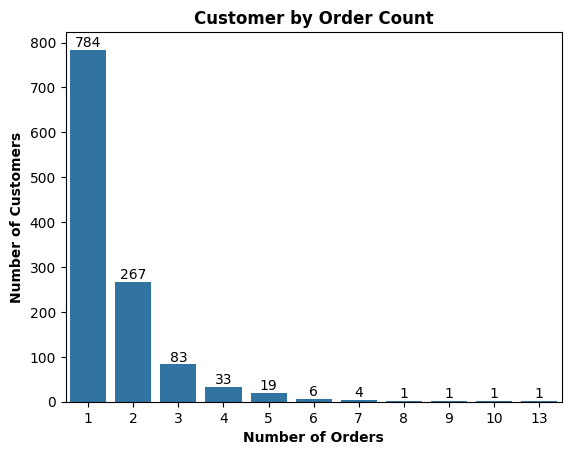

In [15]:
# Create countplot for a order count by unique customers analysis and include count label for number of orders
cust_id_graph = sns.countplot(data=df,x=df['customer_id'].value_counts())
cust_id_graph.set(xlabel='Number of Orders', ylabel='Number of Customers', title='Customer by Order Count')
cust_id_graph.bar_label(cust_id_graph.containers[0])

# Determine countplot formatting
plt.title('Customer by Order Count', fontsize=12, fontweight='bold')
plt.xlabel('Number of Orders', fontsize=10, fontweight='bold')
plt.ylabel('Number of Customers', fontsize=10, fontweight='bold')

# Present countplot
plt.show()

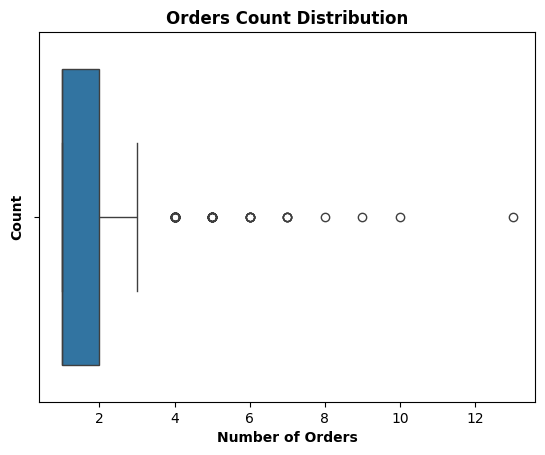

In [16]:
# Generate boxplot for number of orders
cust_id_graph = sns.boxplot(data=df,x=df['customer_id'].value_counts())
cust_id_graph.set(xlabel='Number of Orders', title='Orders Count Distribution')

# Determine boxplot formatting
plt.title('Orders Count Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Number of Orders', fontsize=10, fontweight='bold')
plt.ylabel('Count', fontsize=10, fontweight='bold')

#Present boxplot
plt.show()

#### Observation:

The charts above show that:
- FoodHub received orders from 1200 unique customers.
- Customers placed anywhere from 1 to 13 orders.
- The majority of customers placed a single order (784 customers).
- The distribution of the dataset shows that the 3rd quartile lies at 3 orders, i.e., customers who placed more than 3 orders were the minority.

###**Restaurant Name**

In [17]:
# Check for the number of unique restaurants in the dataset
df['restaurant_name'].nunique()

178

#### Observation:

Orders were placed for 178 restaurants through FoodHub.

###**Cuisine Type**

In [18]:
# Check for the number of unique cuisines in the dataset
df['cuisine_type'].nunique()

14

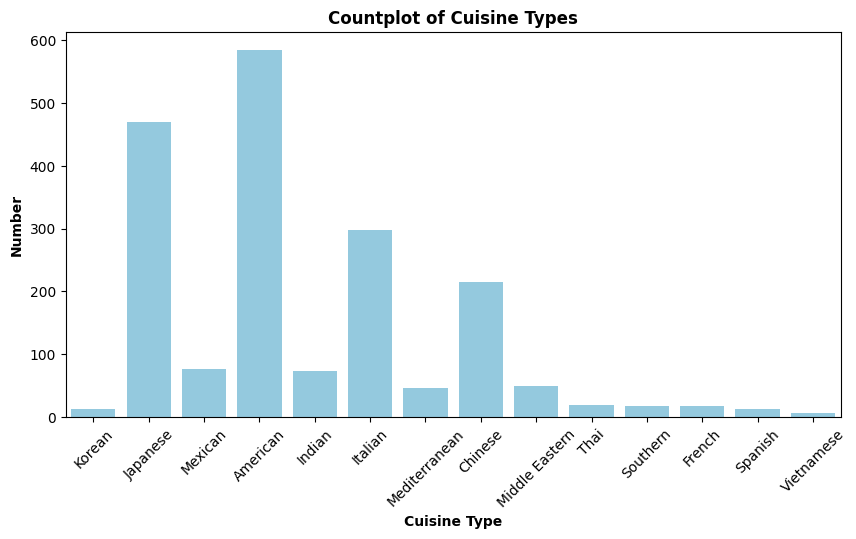

In [19]:
# Create countplot for the different cuisine types in the dataset
plt.figure(figsize = (10,5))
cuis_type_graph = sns.countplot(data = df, x = 'cuisine_type',color='skyblue')

# Determine countplot formatting
plt.title('Countplot of Cuisine Types', fontsize=12, fontweight='bold')
plt.xlabel('Cuisine Type', fontsize=10, fontweight='bold')
plt.ylabel('Number', fontsize=10, fontweight='bold')
plt.xticks(rotation=45)

# Show plot
plt.show()

In [20]:
# List number of orders per cuisine type

df['cuisine_type'].value_counts()

,count
cuisine_type,
American,584
Japanese,470
Italian,298
Chinese,215
Mexican,77
Indian,73
Middle Eastern,49
Mediterranean,46
Thai,19


In [21]:
# Calculate the total number of orders
rows = df.shape[0]

# Generate title for Top Cuisines analysis first section
print('Top 5 Cuisine Types','\n')

# Count the number of orders associated with the 5 most ordered cuisine types
top_5_ct = df['cuisine_type'].value_counts().nlargest(5)
print('Total number of orders associated with the 5 most ordered cuisine types was ',top_5_ct.sum(),'.',sep='')

# Calculate the percentage of orders generated by top 5 cuisine types vs total number of orders
top_5_ct_part = round((top_5_ct.sum()/rows)*100, 2)
print(f'This number represents {top_5_ct_part} % of all orders.')
print("-" * 50)

# Generate title for Top Cuisines analysis second section
print('\n','Top Cuisine Type','\n')

# Determine the top ordered cuisine type and count its number of orders
top_ct_name = df.groupby('cuisine_type').size().idxmax()
top_ct = df['cuisine_type'].value_counts().nlargest(1)
print('The most ordered cuisine type was ',top_ct_name,'.',' It received a total of ',top_ct.sum(),' requests.',sep='')

# Calculate the percentage of orders generated by top cuisine type vs total number of orders
top_ct_part = round((top_ct.sum()/rows)*100, 2)
print(f'This number represents {top_ct_part} % of all orders.')
print("-" * 50)

Top 5 Cuisine Types 

Total number of orders associated with the 5 most ordered cuisine types was 1644.
This number represents 86.62 % of all orders.
--------------------------------------------------

 Top Cuisine Type 

The most ordered cuisine type was American. It received a total of 584 requests.
This number represents 30.77 % of all orders.
--------------------------------------------------


In [22]:
# Calculate the total number of orders
rows = df.shape[0]

# Generate title for Bottom Cuisines analysis first section
print('Bottom 9 Cuisines Types','\n')

# Count the number of orders associated with the 9 least ordered cuisine types
bottom_9_ct = df['cuisine_type'].value_counts().nsmallest(9)
print('Total number of orders associated with the 9 least ordered cuisine types is ',bottom_9_ct.sum(),'.',sep='')

# Calculate the percentage of orders generated by bottom 9 cuisines vs total number of orders
bottom_9_ct_part = round((bottom_9_ct.sum()/rows)*100, 2)
print(f'This number represents {bottom_9_ct_part} % of all orders.')
print("-" * 50)

# Generate title for Bottom Cuisines analysis second section
print('\n','Bottom Cuisine Type','\n')

# Determine the least ordered cuisine type and count its number of orders
bottom_ct_name = df.groupby('cuisine_type').size().idxmin()
bottom_ct = df['cuisine_type'].value_counts().nsmallest(1)
print('The least ordered cuisine type was ',bottom_ct_name,'.',' It received a total of ',bottom_ct.sum(),' requests.',sep='')

# Calculate the percentage of orders generated by top 5 cuisines vs total number of orders
bottom_ct_part = round((bottom_ct.sum()/rows)*100, 2)
print(f'This number represents {bottom_ct_part} % of all orders.')
print("-" * 50)

Bottom 9 Cuisines Types 

Total number of orders associated with the 9 least ordered cuisine types is 254.
This number represents 13.38 % of all orders.
--------------------------------------------------

 Bottom Cuisine Type 

The least ordered cuisine type was Vietnamese. It received a total of 7 requests.
This number represents 0.37 % of all orders.
--------------------------------------------------


#### Observation:

- There are 14 cuisine types available for ordering through FoodHub.
- American cuisine is the most ordered cuisine type, followed by Japanese, Italian, Chinese and Mexican.
- The top 5 most ordered cuisine types represent 86.62% of all orders.
- The American cuisine alone represented 30.77% of all orders (584 orders in total).
- The 9 least ordered cuisine types represent 13.38% of all orders.
- The least order cuisine type was Vietnamese - it only represented 0.37% of all orders (7 orders in total).

###**Cost of the Order**

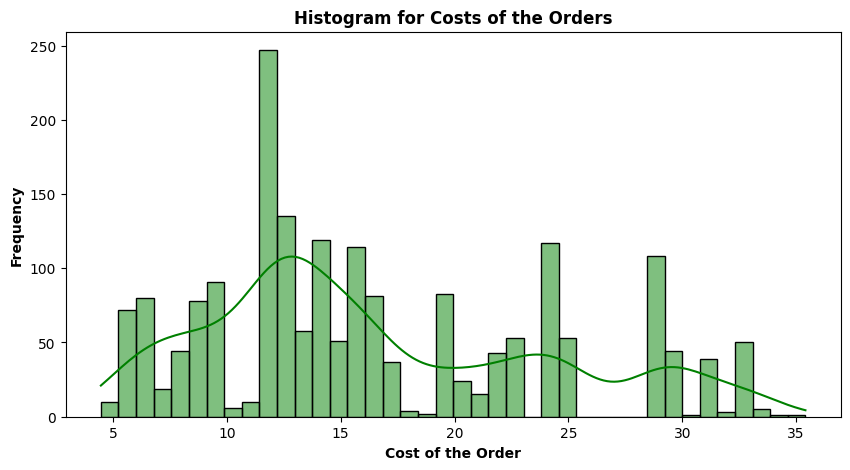

In [23]:
# Plot a histogram for the cost of the order values
plt.figure(figsize=(10, 5))
sns.histplot(df['cost_of_the_order'], bins=40, color='green', edgecolor='black', kde=True)

# Determine histogram formatting
plt.title('Histogram for Costs of the Orders', fontsize=12, fontweight='bold')
plt.xlabel('Cost of the Order', fontsize=10, fontweight='bold')
plt.ylabel('Frequency', fontsize=10, fontweight='bold')

# Present histogram
plt.show()

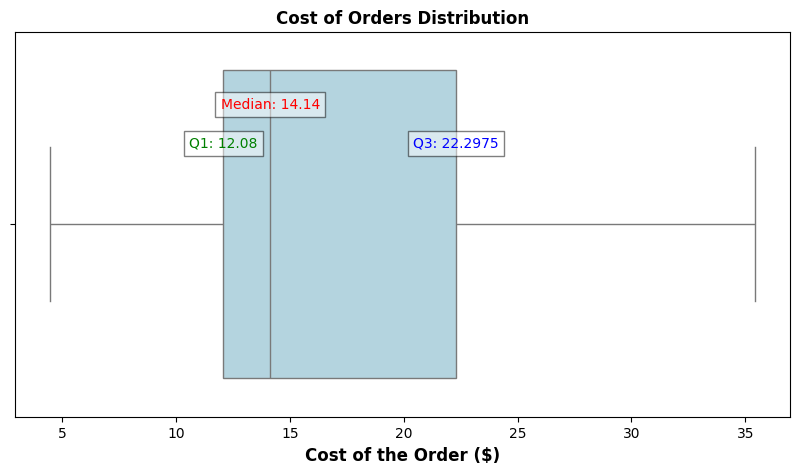

In [24]:
# Create boxplot for the cost of the order variable
plt.figure(figsize=(10, 5))
box_plot = sns.boxplot(x=df['cost_of_the_order'],color='lightblue')

# Calculate quartiles and median
Q1 = df['cost_of_the_order'].quantile(0.25)
Q3 = df['cost_of_the_order'].quantile(0.75)
median = df['cost_of_the_order'].median()

# Determine boxplot formatting
plt.text(x=median, y=-0.3, s=f'Median: {median}', color='red', ha='center', bbox=dict(facecolor='white', alpha=0.5))
plt.text(x=Q1, y=-0.2, s=f'Q1: {Q1}', color='green', ha='center', bbox=dict(facecolor='white', alpha=0.5))
plt.text(x=Q3, y=-0.2, s=f'Q3: {Q3}', color='blue', ha='center', bbox=dict(facecolor='white', alpha=0.5))
plt.xlabel('Cost of the Order ($)', fontsize=12, fontweight='bold')
plt.title('Cost of Orders Distribution', fontsize=12, fontweight='bold')

# Show boxplot
plt.show()

In [25]:
min_value_coto = df['cost_of_the_order'].min(skipna = False)
print('The order with the lowest cost was $ ',min_value_coto,'.',sep='')

max_value_coto = df['cost_of_the_order'].max(skipna = False)
print('The order with the highest cost was $ ',max_value_coto,'.',sep='')

The order with the lowest cost was $ 4.47.
The order with the highest cost was $ 35.41.


#### Observation:

- The order with the lowest cost was 4.47 dollars.
- The order with the highest cost was 35.41 dollars.
- The median order cost was 14.14 dollars.
- When looking at the cost distribution, it can be observed that the 1st quartile was 12.08 dollars and the 3rd quartile was 22.30 dollars.

###**Day of the Week**

In [26]:
# Check the number of unique values for day of the week
numb_days_week = df['day_of_the_week'].nunique()
print('There are ',numb_days_week,' unique days of the week.',sep='')

# Check the names of the unique values for day of the week
names_of_days = df['day_of_the_week'].unique()
print('The days of the week are ',' and '.join(names_of_days),'.',sep='')

There are 2 unique days of the week.
The days of the week are Weekend and Weekday.


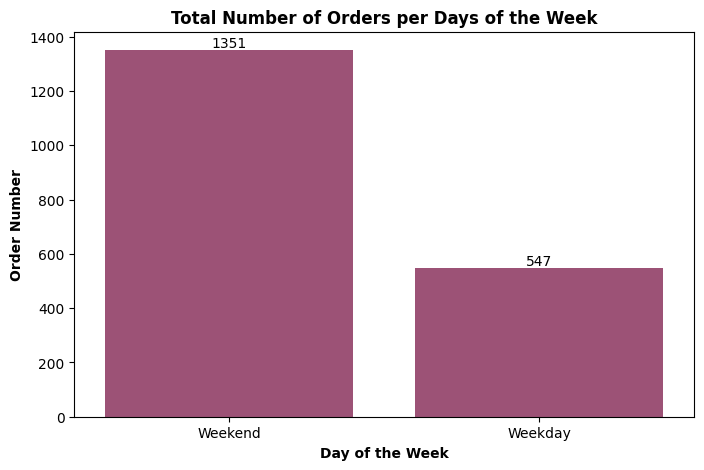

In [27]:
# Create a countplot for the number of order per days of the week
plt.figure(figsize=(8, 5))
numb_week_graph = sns.countplot(data = df, x = 'day_of_the_week', color='#a84676')
numb_week_graph.bar_label(numb_week_graph.containers[0])

# Determine plot formatting
plt.title('Total Number of Orders per Days of the Week', fontsize=12, fontweight='bold')
plt.xlabel('Day of the Week', fontsize=10, fontweight='bold')
plt.ylabel('Order Number', fontsize=10, fontweight='bold')

# Present the plot
plt.show()

#### Observation:

- Only two "group of days" of the week are captured with FoodHub orders, Weekdays and Weekends. Actual days of the week are not captured.
- The majority of orders is placed on Weekends.

Out of the total 1898 orders:
  - 1351 orders were placed on Weekends.
  - 547 orders were placed on Weekdays.

###**Rating**

In [28]:
# Check the number of unique values for rating
rating_numb = df['rating'].nunique()
print('There are ',rating_numb,' unique rating levels.',sep='')

# Check the value of the unique rating levels
rating_names = df['rating'].unique()
print('The values are: ',' , '.join(rating_names),'.',sep='')

There are 4 unique rating levels.
The values are: Not given , 5 , 3 , 4.


In [29]:
# Generate title section
print('Rating Count Per Rating Level','\n')

# Generate a value count for the data captured in the rating property
df_cols_str = ['rating']

for column in df_cols_str:
  print(df[column].value_counts())
  print("-" * 50)

Rating Count Per Rating Level 

rating
Not given    736
5            588
4            386
3            188
Name: count, dtype: int64
--------------------------------------------------


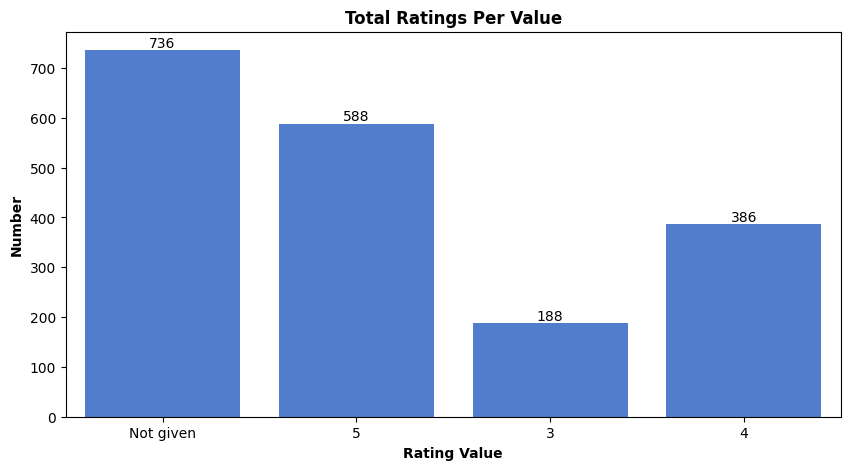

In [30]:
# Generate a countplot for number of ratings
plt.figure(figsize=(10,5))
rating_graph = sns.countplot(data = df, x = 'rating', color='#3d77e0')
rating_graph.bar_label(rating_graph.containers[0])

# Determine countplot formatting
plt.title('Total Ratings Per Value', fontsize=12, fontweight='bold')
plt.xlabel('Rating Value', fontsize=10, fontweight='bold')
plt.ylabel('Number', fontsize=10, fontweight='bold')

# Present the plot
plt.show()

In [31]:
# Calculate the total number of orders
rows = df.shape[0]

# Generate title section
print('Unrated Orders','\n')

# Calculate number of unrated orders
unrated_orders = 'Not given'
total_unrated_orders = df['rating'].value_counts()[unrated_orders]
print('A rate was not given for ',total_unrated_orders,' orders.',sep='')

# Calculate the percentage of orders not rated vs total number of orders
unrated_orders_part = round((total_unrated_orders.sum()/rows)*100, 2)
print(f'This number represents {unrated_orders_part} % of all orders.')

Unrated Orders 

A rate was not given for 736 orders.
This number represents 38.78 % of all orders.


In [32]:
# Calculate the total number of orders
rows = df.shape[0]

# Generate title section
print('\n','Rated Orders','\n')

# Calculate number of rated orders
rated_order_3 = '3'
rated_order_4 = '4'
rated_order_5 = '5'
total_rated_orders = df['rating'].value_counts()[rated_order_3] + df['rating'].value_counts()[rated_order_4] + df['rating'].value_counts()[rated_order_5]
print('A rate was given for ',total_rated_orders.sum(),' orders.',sep='')

# Calculate the percentage of rated orders vs total number of orders and total rated orders
total_rated_orders_part = round((total_rated_orders.sum()/rows)*100, 2)
print(f'This number represents {total_rated_orders_part} % of all orders.')
print("-" * 50)

# Determine the number of orders rated 5
rated_order_5 = '5'
total_rated_5_orders = df['rating'].value_counts()[rated_order_5]
print('A rate of 5 was given for ',total_rated_5_orders.sum(),' orders.',sep='')

# Calculate the percentage of orders generated by raiting 5 vs total number of orders and total rated orders
rating_5_part_total = round((total_rated_5_orders.sum()/rows)*100, 2)
rating_5_part_rated = round((total_rated_5_orders.sum()/total_rated_orders.sum())*100, 2)
print(f'This number represents {rating_5_part_total} % of all orders and {rating_5_part_rated} % of rated orders.')
print("-" * 50)


# Determine the number of orders rated 4
rated_order_4 = '4'
total_rated_4_orders = df['rating'].value_counts()[rated_order_4]
print('A rate of 4 was given for ',total_rated_4_orders.sum(),' orders.',sep='')

# Calculate the percentage of orders generated by raiting 5 vs total number of orders and total rated orders
rating_4_part_total = round((total_rated_4_orders.sum()/rows)*100, 2)
rating_4_part_rated = round((total_rated_4_orders.sum()/total_rated_orders.sum())*100, 2)
print(f'This number represents {rating_4_part_total} % of all orders and {rating_4_part_rated} % of rated orders.')
print("-" * 50)

# Determine the number of orders rated 3
rated_order_3 = '3'
total_rated_3_orders = df['rating'].value_counts()[rated_order_3]
print('A rate of 3 was given for ',total_rated_3_orders.sum(),' orders.',sep='')

# Calculate the percentage of orders generated by raiting 5 vs total number of orders and total rated orders
rating_3_part_total = round((total_rated_3_orders.sum()/rows)*100, 2)
rating_3_part_rated = round((total_rated_3_orders.sum()/total_rated_orders.sum())*100, 2)
print(f'This number represents {rating_3_part_total} % of all orders and {rating_3_part_rated} % of rated orders.')


 Rated Orders 

A rate was given for 1162 orders.
This number represents 61.22 % of all orders.
--------------------------------------------------
A rate of 5 was given for 588 orders.
This number represents 30.98 % of all orders and 50.6 % of rated orders.
--------------------------------------------------
A rate of 4 was given for 386 orders.
This number represents 20.34 % of all orders and 33.22 % of rated orders.
--------------------------------------------------
A rate of 3 was given for 188 orders.
This number represents 9.91 % of all orders and 16.18 % of rated orders.


In [33]:
# Calculate the total number of orders
rows = df.shape[0]

# Calculate number of rated orders
rated_order_3 = '3'
rated_order_4 = '4'
rated_order_5 = '5'
total_rated_orders = df['rating'].value_counts()[rated_order_3] + df['rating'].value_counts()[rated_order_4] + df['rating'].value_counts()[rated_order_5]

# Generate title section
print('FoodHub CSAT Results')
print('\n')

# Calculate number of satisfied customers
satisfied_customers = df['rating'].value_counts()[rated_order_4] + df['rating'].value_counts()[rated_order_5]
print('The total of satisfied customers (rates 4 and 5) was ',satisfied_customers.sum(),'.',sep='')

# Calculate CSAT based on rated orders only (standard CSAT method)
foodhub_csat = int(round((satisfied_customers.sum()/total_rated_orders.sum())*100, 0))
print('The FoodHub CSAT (rated orders only) was ',foodhub_csat,'%.',sep='')

FoodHub CSAT Results


The total of satisfied customers (rates 4 and 5) was 974.
The FoodHub CSAT (rated orders only) was 84%.


#### Observation:

- Even though the rating scale goes from 1 - 5, rates were only given for the values 3, 4 and 5 (which is highly unlikely in a dataset of this size).

Continuing the observations in the assumption that the data is correct:
- 61.22 % of orders were rated, leaving 38.78% of orders unrated.
- Of the total rated orders:
    - 50.60 % were rated 5 (30.98 % of all orders)
    - 33.22 % were rated 4 (20.34 % of all orders)
    - 16.18 % were rated 3 (9.91 % of all orders)

FoodHub’s CSAT, measured as the share of rated orders scored 4 or 5, was 84% (974 of 1,162 rated orders). Because 39% of orders went unrated, this reflects only customers who chose to respond.


###**Food Preparation Time**

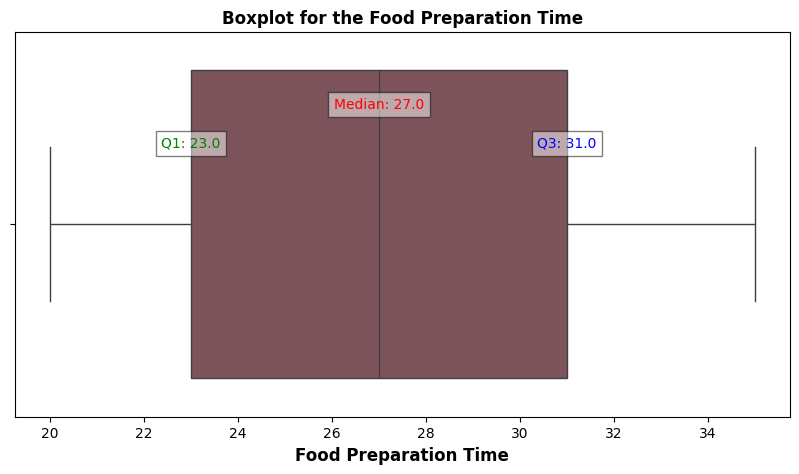

In [34]:
# Generate boxplot for food preparation time
plt.figure(figsize=(10, 5))
box_plot = sns.boxplot(x=df['food_preparation_time'],color='#854d58')

# Calculate food preparation time quartiles and median
Q1 = df['food_preparation_time'].quantile(0.25)
Q3 = df['food_preparation_time'].quantile(0.75)
median = df['food_preparation_time'].median()

# Determine boxplot formatting
plt.text(x=median, y=-0.3, s=f'Median: {median}', color='red', ha='center', bbox=dict(facecolor='white', alpha=0.5))
plt.text(x=Q1, y=-0.2, s=f'Q1: {Q1}', color='green', ha='center', bbox=dict(facecolor='white', alpha=0.5))
plt.text(x=Q3, y=-0.2, s=f'Q3: {Q3}', color='blue', ha='center', bbox=dict(facecolor='white', alpha=0.5))
plt.xlabel('Food Preparation Time', fontsize=12, fontweight='bold')
plt.title('Boxplot for the Food Preparation Time', fontsize=12, fontweight='bold')

# Present boxplot
plt.show()

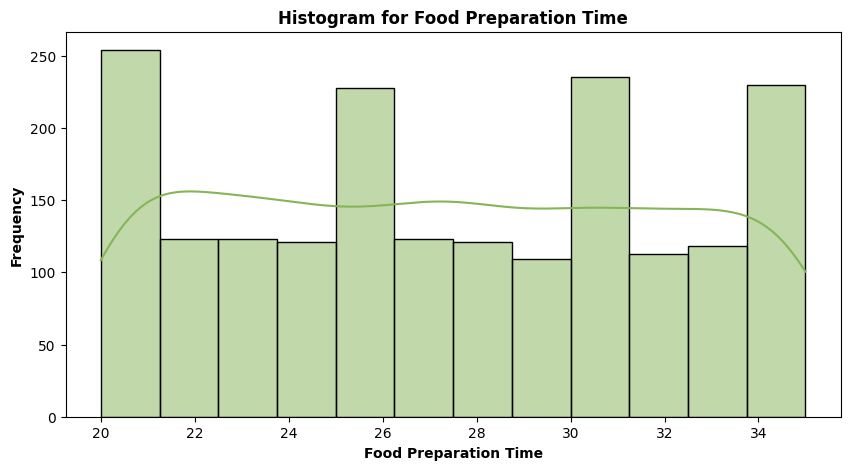

In [35]:
# Plot a histogram for food preparation time
plt.figure(figsize=(10, 5))
sns.histplot(df['food_preparation_time'], color='#85b557', edgecolor='black', kde=True)

# Determine histogram formatting
plt.title('Histogram for Food Preparation Time', fontsize=12, fontweight='bold')
plt.xlabel('Food Preparation Time', fontsize=10, fontweight='bold')
plt.ylabel('Frequency', fontsize=10, fontweight='bold')

# Present histogram
plt.show()

#### Observation:
- Once placed, orders take at least 20 minutes to be prepared.
- The average time that it takes for a food to be prepared is 27 minutes, with 75% of them taking 31 minutes or less.

###**Delivery Time**

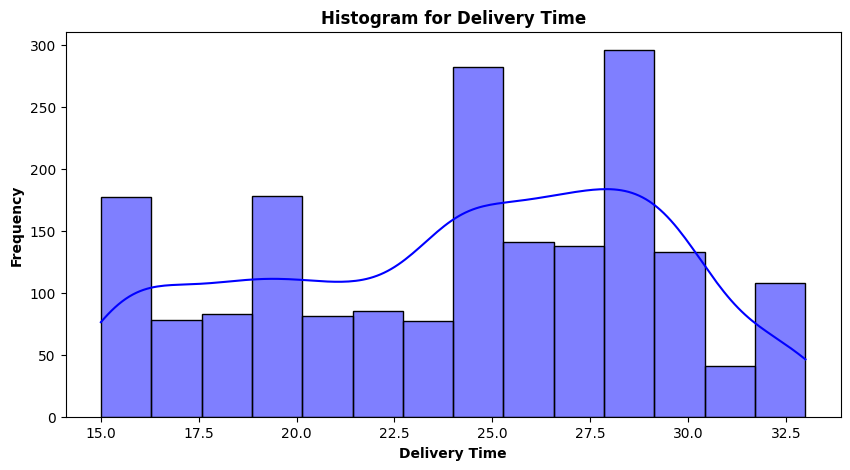

In [36]:
# Plot a histogram for delivery time
plt.figure(figsize=(10, 5))
sns.histplot(df['delivery_time'], color='blue', edgecolor='black', kde=True)

# Determine histogram formatting
plt.title('Histogram for Delivery Time', fontsize=12, fontweight='bold')
plt.xlabel('Delivery Time', fontsize=10, fontweight='bold')
plt.ylabel('Frequency', fontsize=10, fontweight='bold')

# Present histogram
plt.show()

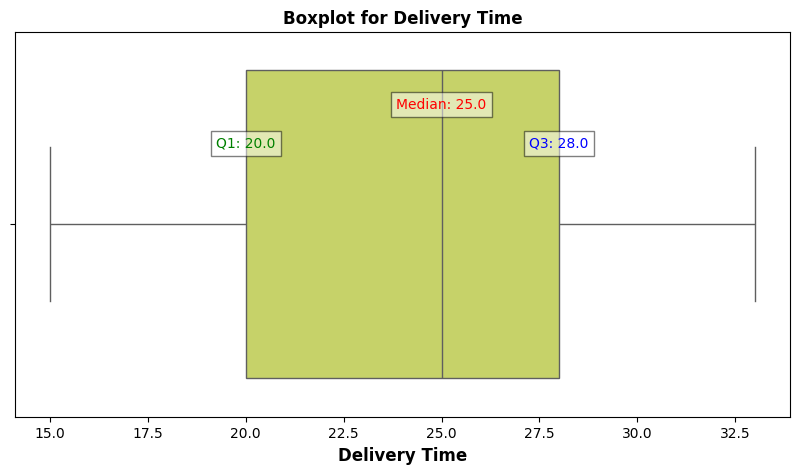

In [37]:
# Generate boxplot for delivery time
plt.figure(figsize=(10, 5))
box_plot = sns.boxplot(x=df['delivery_time'],color='#d4e457')

# Calculate food preparation time quartiles and median
Q1 = df['delivery_time'].quantile(0.25)
Q3 = df['delivery_time'].quantile(0.75)
median = df['delivery_time'].median()

# Determine boxplot formatting
plt.text(x=median, y=-0.3, s=f'Median: {median}', color='red', ha='center', bbox=dict(facecolor='white', alpha=0.5))
plt.text(x=Q1, y=-0.2, s=f'Q1: {Q1}', color='green', ha='center', bbox=dict(facecolor='white', alpha=0.5))
plt.text(x=Q3, y=-0.2, s=f'Q3: {Q3}', color='blue', ha='center', bbox=dict(facecolor='white', alpha=0.5))
plt.xlabel('Delivery Time', fontsize=12, fontweight='bold')
plt.title('Boxplot for Delivery Time', fontsize=12, fontweight='bold')

# Present boxplot
plt.show()

#### Observation:

- On average, it takes around 24 minutes for orders to be delivered after they are picked up from the restaurant.
- The fastest deliveries are 15 mins and the slowest deliveries take up to 33 minutes

### 7. Which restaurants drive the most orders?

In [38]:
# Get top 5 restaurants with highest number of orders
df['restaurant_name'].value_counts()[0:5]

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### Observations:

The top 5 restaurants considering number of orders received were:
- Shake Shack (219 orders received)
- The Meatball Shop (132 orders received)
- Blue Ribbon Sushi (119 orders received)
- Blue Ribbon Fried Chickek (96 orders received)
- Parm (68 orders received)


### 8. Which cuisine is most popular on weekends?

In [39]:
# Select only Weekend orders
df_weekend = df[df['day_of_the_week'] == 'Weekend']

# Calculate most popular cuisine type and the number of orders for weekends
cuisine_counts = df_weekend['cuisine_type'].value_counts()
most_popular_cuisine = cuisine_counts.idxmax()
number_of_orders = cuisine_counts.max()

# Print simple output of the most popular cuisine type and the number of orders for weekends.
print(f'The most popular cuisine type on weekends is {most_popular_cuisine} with {number_of_orders} orders.')

The most popular cuisine type on weekends is American with 415 orders.


#### Observations:

The most popular cuisine type on weekends is American with 415 orders.

### 9. What share of orders cost more than $20?

In [40]:
# Calculate total number of orders that cost 20 dollars and their % against total
total_orders =len(df.index)
total_orders_more_than_20 =len(df[df["cost_of_the_order"]>20])
percent_of_orders_above_20 =(total_orders_more_than_20 /total_orders) *100
print('The percentage of orders above $20 is %.2f%%' %percent_of_orders_above_20,'.',sep='')

The percentage of orders above $20 is 29.24%.


#### Observations:

The percentage of orders above $20 is 29.24%.

### 10. How long does delivery take on average?

In [41]:
# Generate order delivery time mean
df['delivery_time'].mean()

np.float64(24.161749209694417)

#### Observations:

The mean of the delivery time is 24.16 minutes.

### 11. Who are the most frequent customers? (Eligible for a 20% loyalty voucher)

In [42]:
# Print the customer ID for top 3 customers
print(df.groupby(['customer_id'])['order_id'].count().nlargest(3).to_string())

customer_id
52832    13
47440    10
83287     9


#### Observations:

The IDs of the top 3 most frequent customers and number of orders they placed is:
  - Customer ID 52832 (placed 13 orders)
  - Customer ID 47440 (placed 10 orders)
  - Customer ID 83287 (placed 9 orders)


### Multivariate Analysis

### 12. How do the key variables relate to each other?


**Cuisine vs Cost of the Order**

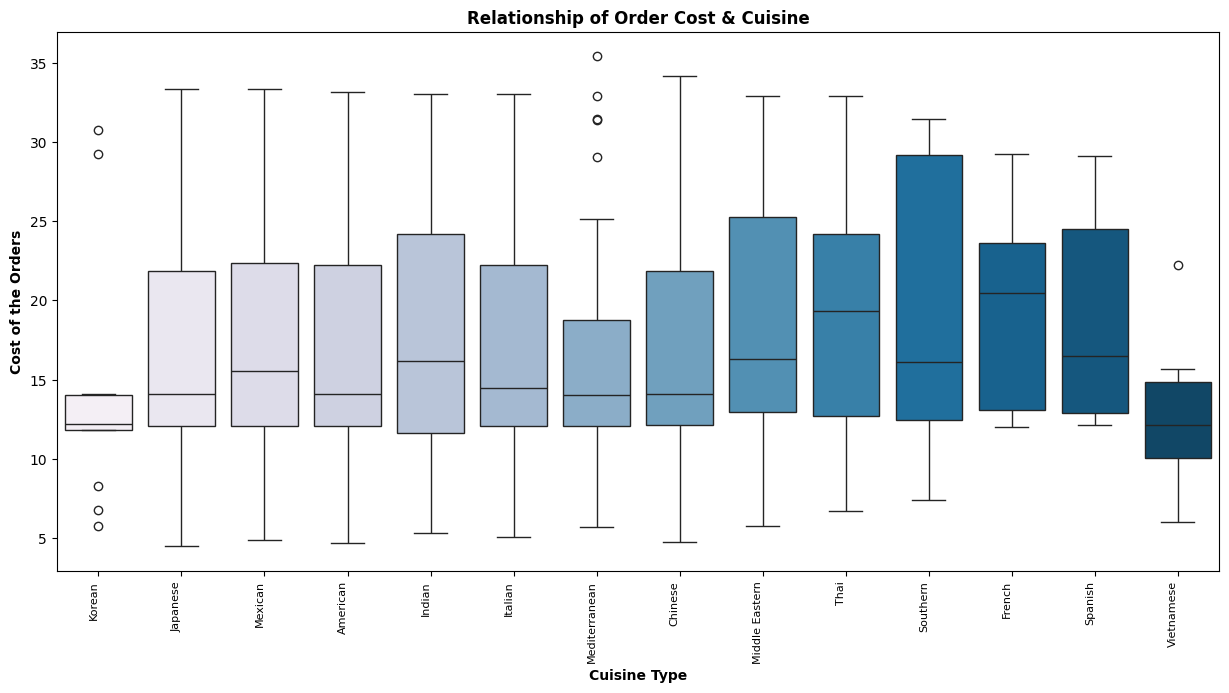

In [43]:
# Review relationship between cost of the order and cuisine type
plt.figure(figsize=(15,7))

# Create a boxplot to show the relationship between cost of the order and cuisine type
sns.boxplot(x = 'cuisine_type', y = 'cost_of_the_order', data = df, palette = 'PuBu', hue = 'cuisine_type')

# Determine boxplot formatting
plt.xlabel('Cuisine Type', fontsize=10, fontweight='bold')
plt.ylabel('Cost of the Orders', fontsize=10, fontweight='bold')
plt.title('Relationship of Order Cost & Cuisine', fontsize=12, fontweight='bold')
plt.xticks(rotation=90, fontsize=8, horizontalalignment='right')

# Present the plot
plt.show()

The cuisine types Korean, Mediterranean and Vietnamese have outliers. This may indicate out of the ordinary order costs because of large or small orders, or potentially incorrectly entered data. There are also long whiskers for the more popular cuisines that represents a high variability in the data.

The median for the majority of cuisine types is closer to the bottom/left that represents a right skewed distribution, i.e., most of the order costs are in the lower range, approximately 15 dollars to 17 dollars.



**Cuisine vs Food Preparation time**


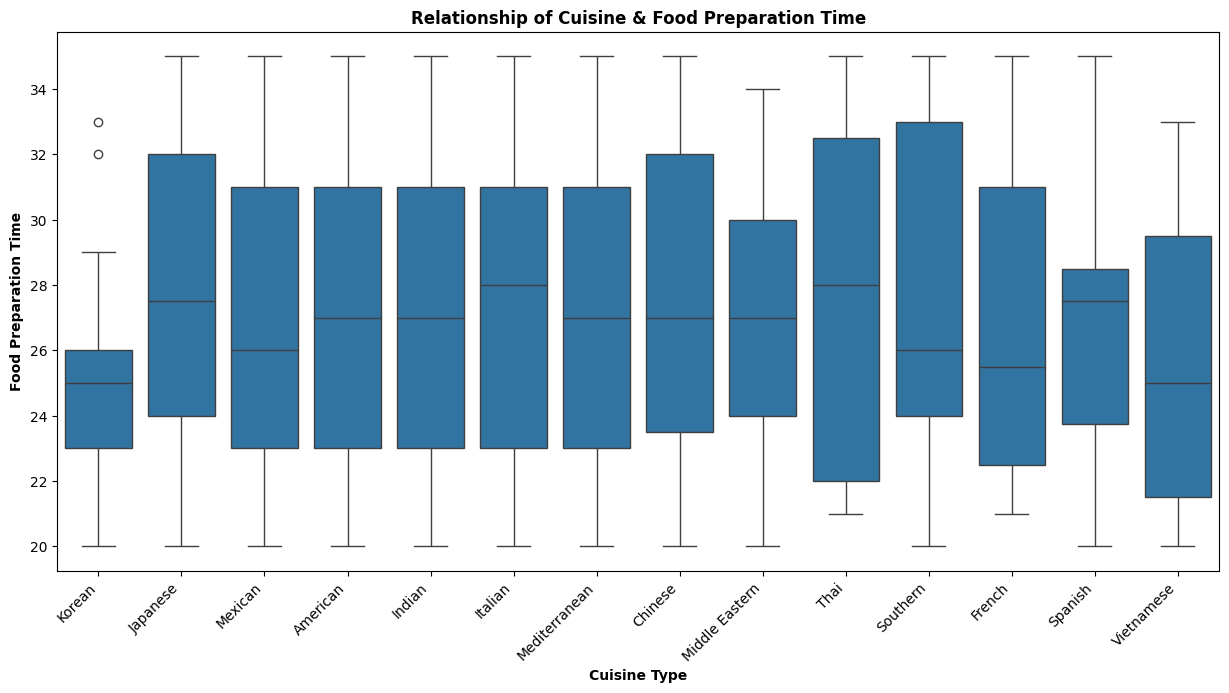

In [44]:
# Review the relationship between cost of the order and cuisine type
plt.figure(figsize=(15,7))

# Create a boxplot to show the relationship between cost of the order and cuisine type
sns.boxplot(x = 'cuisine_type', y = 'food_preparation_time', data = df)

# Determine boxplot formatting
plt.xlabel('Cuisine Type', fontsize=10, fontweight='bold')
plt.ylabel('Food Preparation Time', fontsize=10, fontweight='bold')
plt.title('Relationship of Cuisine & Food Preparation Time', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, fontsize=10, horizontalalignment='right')

# Present the plot
plt.show()

Preparation times are consistently high across all cuisines, with no cuisine standing out as notably faster. Because this metric also includes time spent waiting for the driver to pick up the order, the data can’t show whether long times come from kitchen capacity or driver availability. That’s why separating the two measurements is one of the key recommendations below.

**Day of the Week vs Delivery time**


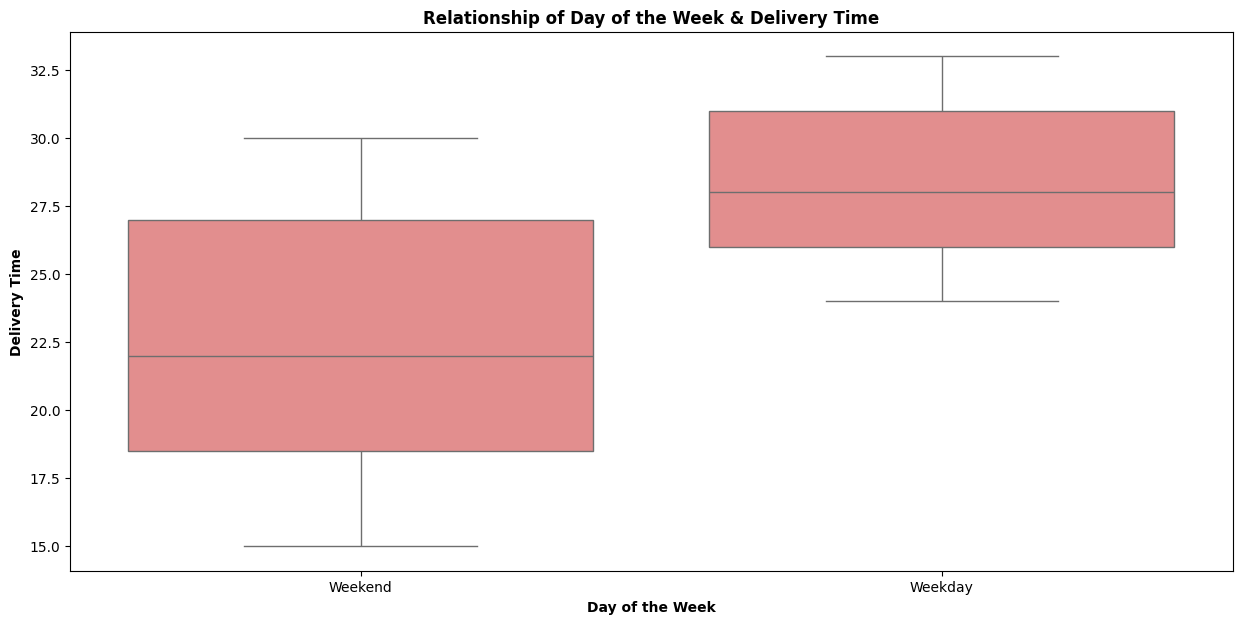

In [45]:
# Review the relationship between day of the week and delivery time
plt.figure(figsize=(15,7))

# Create a boxplot to show the relationship between day of the week and delivery time
sns.boxplot(x = 'day_of_the_week', y = 'delivery_time', data = df, color='lightcoral')

# Determine boxplot formatting
plt.xlabel('Day of the Week', fontsize=10, fontweight='bold')
plt.ylabel('Delivery Time', fontsize=10, fontweight='bold')
plt.title('Relationship of Day of the Week & Delivery Time', fontsize=12, fontweight='bold')
plt.xticks(rotation=0, fontsize=10, horizontalalignment='center')

# Present the plot
plt.show()

Weekday deliveries take longer than weekend deliveries (mean of 28.3 vs. 22.5 minutes) and vary more. Possible explanations include weekday traffic or fewer drivers on shift; both are worth validating with driver supply data, since slower weekday service may be one reason weekday orders are lower.



**Rating vs Delivery time**


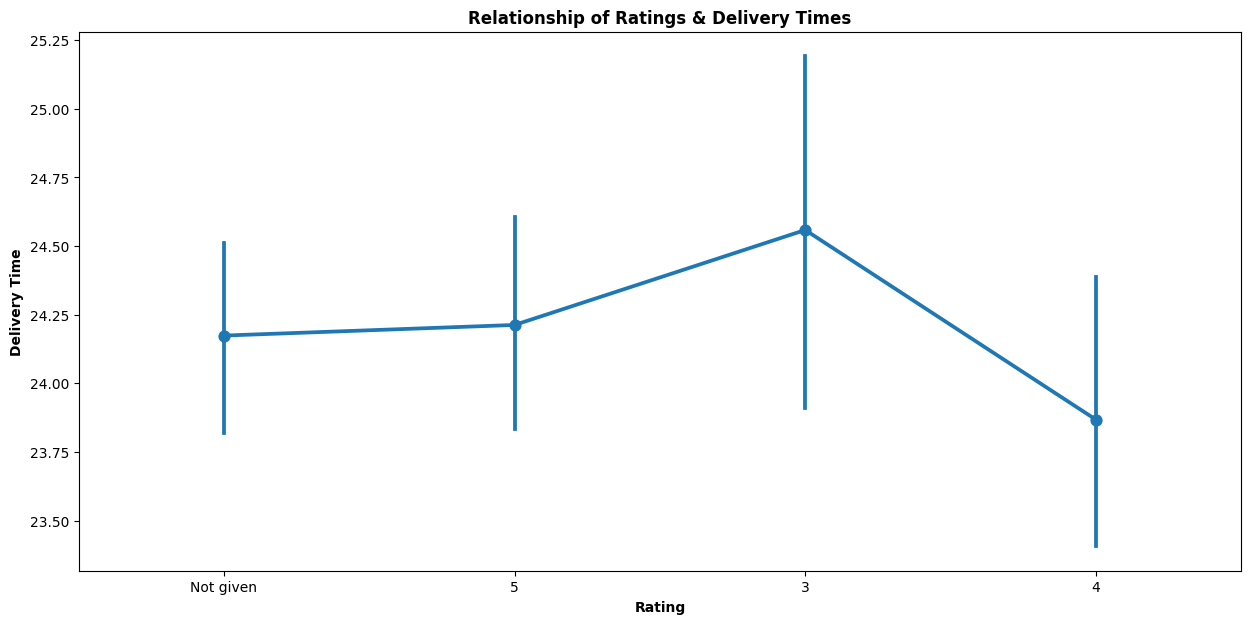

In [46]:
# Review the relationship between day of the week and delivery time
plt.figure(figsize=(15,7))

# Create a boxplot to show the relationship between day of the week and delivery time
sns.pointplot(x = 'rating', y = 'delivery_time', data = df)

# Set the labels, title, position, fontsize and alignment for the bar chart output
plt.xlabel('Rating', fontsize=10, fontweight='bold')
plt.ylabel('Delivery Time', fontsize=10, fontweight='bold')
plt.title('Relationship of Ratings & Delivery Times', fontsize=12, fontweight='bold')
plt.xticks(rotation=0, fontsize=10, horizontalalignment='center')

# Show the plot
plt.show()

Delivery times are similar for unrated and 5-star orders. Orders rated 3 show the widest spread of delivery times, consistent with slow deliveries contributing to lower satisfaction. Orders rated 4 show lower delivery times than expected, which is counterintuitive and suggests other factors drive the difference between a 4 and a 5. Collecting more ratings, across the full 1–5 range, would make this relationship clearer and help identify which restaurants need to improve.

**Rating vs Food preparation time**


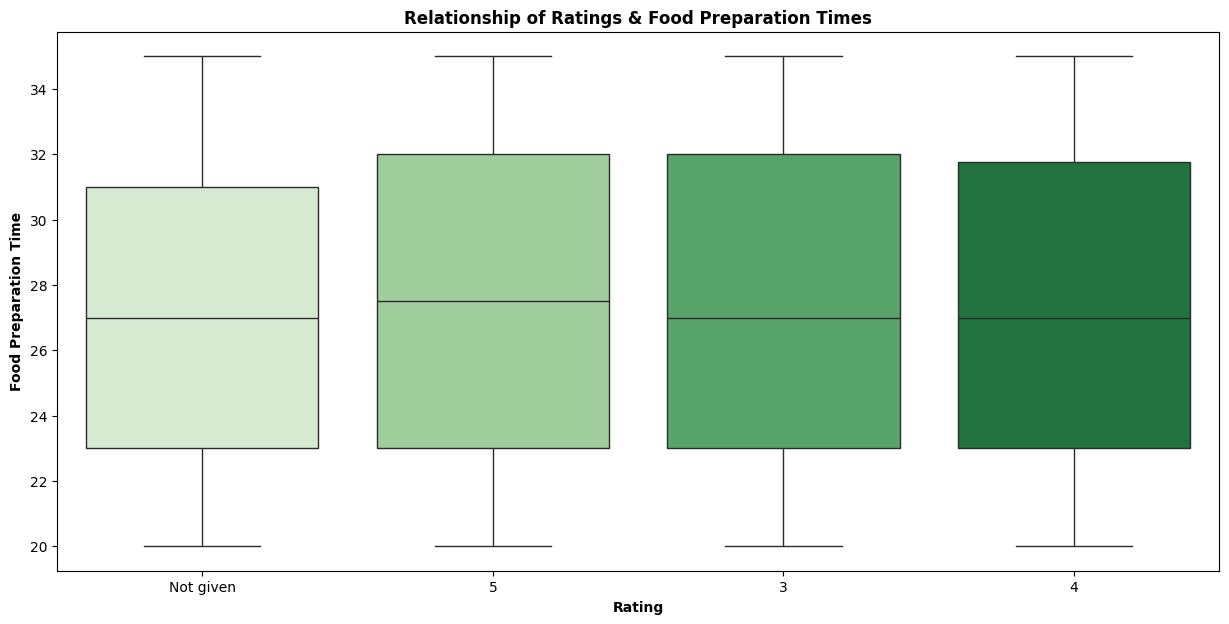

In [47]:
# Review the relationship between day of the week and delivery time
plt.figure(figsize=(15,7))

# Create a boxplot to show the relationship between rating and preparation time
sns.boxplot(x='rating', y='food_preparation_time', data=df, palette='Greens', hue='rating')

# Determine boxplot formatting
plt.xlabel('Rating', fontsize=10, fontweight='bold')
plt.ylabel('Food Preparation Time', fontsize=10, fontweight='bold')
plt.title('Relationship of Ratings & Food Preparation Times', fontsize=12, fontweight='bold')
plt.xticks(rotation=0, fontsize=10, horizontalalignment='center')

# Present the plot
plt.show()

Preparation times are tightly concentrated at every rating level, so preparation time alone doesn’t appear to explain differences in ratings. Customers experience preparation and delivery as one total wait, so total time from order to door is likely a better lens on satisfaction (see Q15).

**Rating vs Cost of the order**


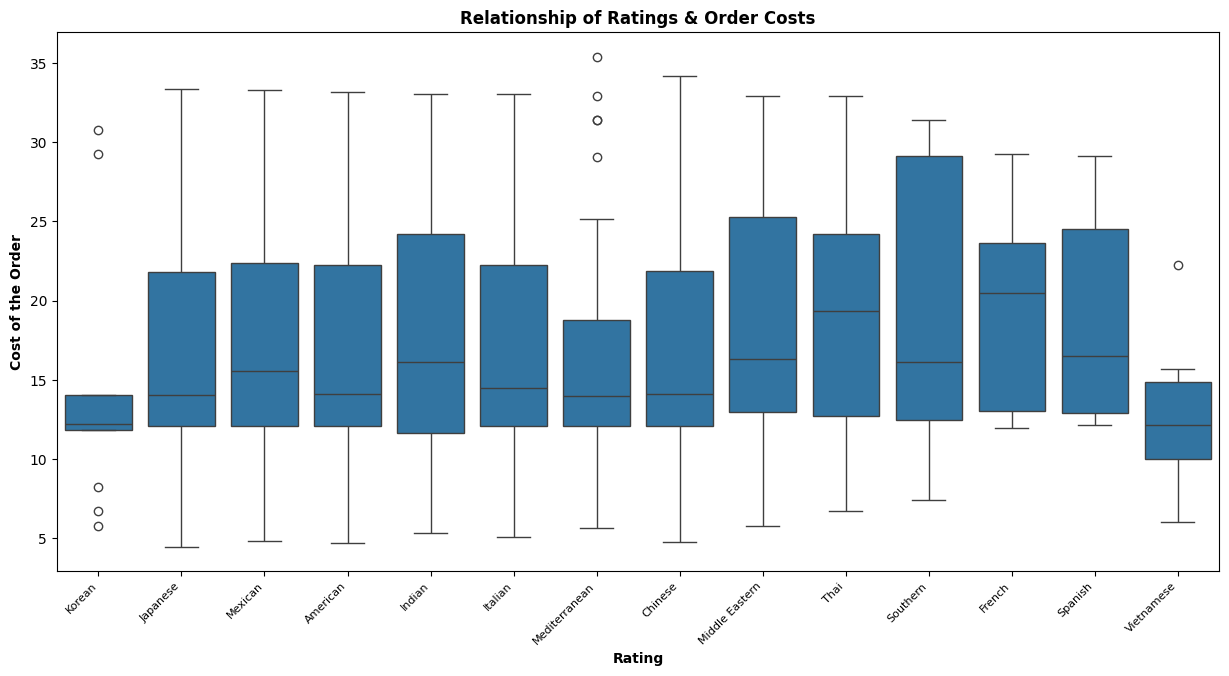

In [48]:
# Examine the relationship between rating and cost of the order
plt.figure(figsize=(15,7))

# Create a boxplot to show the relationship between rating and preparation time
sns.boxplot(x='cuisine_type', y='cost_of_the_order', data=df)

# Set the labels, title, position, fontsize and alignment for the bar chart output
plt.xlabel('Rating', fontsize=10, fontweight='bold')
plt.ylabel('Cost of the Order', fontsize=10, fontweight='bold')
plt.title('Relationship of Ratings & Order Costs', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, fontsize=8, horizontalalignment='right')
plt.xticks(rotation = 45)

# Show the plot
plt.show()

Order cost varies widely within every rating level, with no clear pattern between how much customers spend and how they rate. The data can’t show whether low or missing ratings are driven by price, wait time, or food quality. Adding optional one-tap feedback reasons (for example “late,” “cold,” or “expensive”) to the rating prompt would answer that.



**Correlation among variables**


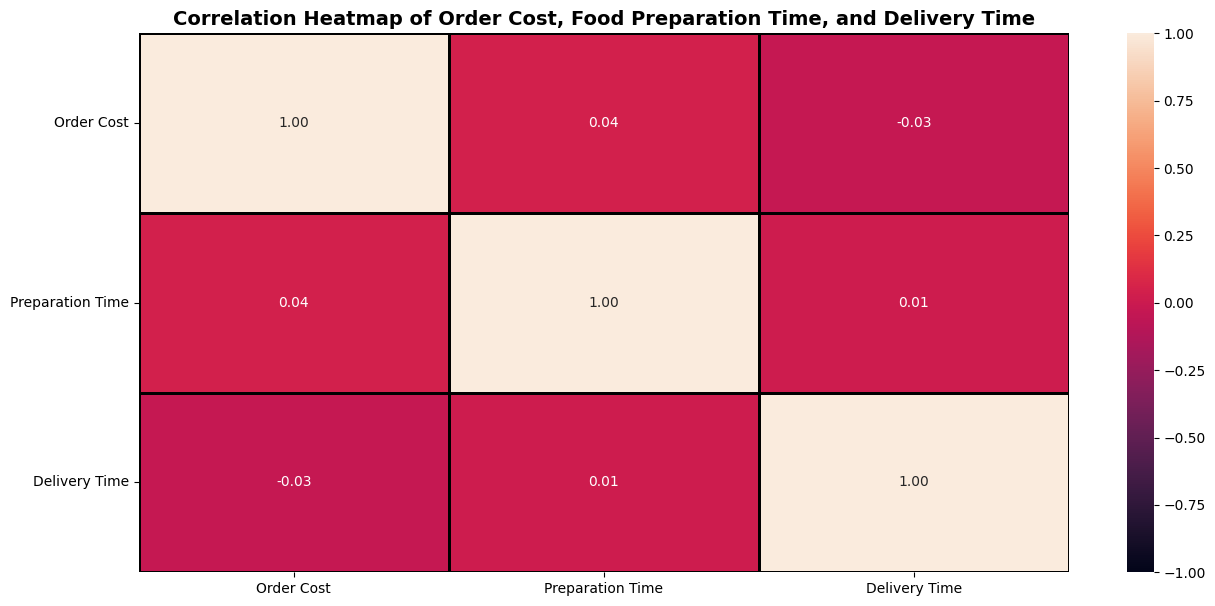

In [49]:
# Create a list of columns to include in the correlation matrix
col_list = ['cost_of_the_order', 'food_preparation_time', 'delivery_time']

# Create a new df with the correlation matrix
corr_df = df[col_list].corr()

# Rename  columns
corr_df.columns = ['Order Cost', 'Preparation Time', 'Delivery Time']
corr_df.index = ['Order Cost', 'Preparation Time', 'Delivery Time']

plt.figure(figsize=(15, 7))

# Add a title to the heatmap
plt.title('Correlation Heatmap of Order Cost, Food Preparation Time, and Delivery Time', fontsize=14, fontweight='bold')

# Create a heatmap with a custom color map and add annotations to the heatmap.
sns.heatmap(corr_df, annot=True, vmin=-1, vmax=1, fmt='.2f', linewidths=1, linecolor='black')

# Rotate the y-axis labels
plt.yticks(rotation=0)

# Present plot
plt.show()

Order cost, preparation time, and delivery time are essentially uncorrelated (all coefficients between -0.03 and 0.04). Larger or more expensive orders don’t take longer to prepare or deliver, which means wait times are driven by operational factors, such as kitchen capacity, driver availability, and day of the week, rather than by order size. Those operational processes are the main lever for improving the customer experience.



### 13. Which restaurants qualify for the promotional offer? (More than 50 ratings and an average above 4)

In [50]:
# Find the restaurants that are not rated ('Not given') and create a df
restaurants_not_rated_df = df[df['rating'] != 'Not given'].copy()

# Convert rating to integer data type
restaurants_not_rated_df['rating'] = restaurants_not_rated_df['rating'].astype('int')

# Groups the restaurants by name and calculates the count and mean of ratings
ratings_count_df = restaurants_not_rated_df.groupby(['restaurant_name'])['rating'].agg(['count', 'mean']).reset_index()

# Select restaurants with a rating higher than 50 and a mean rating higher than 4
restaurants_promo_df = ratings_count_df[(ratings_count_df['count'] > 50) & (ratings_count_df['mean'] > 4)]

# Output the restaurants sorted by the mean rating of 4
restaurants_promo_df.head()

,restaurant_name,count,mean
16,Blue Ribbon Fried Chicken,64,4.328125
17,Blue Ribbon Sushi,73,4.219178
117,Shake Shack,133,4.278195
132,The Meatball Shop,84,4.511905


#### Observations:

The restaurants that fulfill the criteria to get the promotional offer are:

- Blue Ribbon Fried Chichen (total of 64 ratings with an average rating of 4.32)
- Blue Ribbon Sushi (total of 73 ratings with an average rating of 4.21)
- Shake Shack (total of 133 ratings with an average rating of 4.27)
- The Meatball Shop (total of 84 ratings with an average rating of 4.51)


### 14. How much net revenue does the commission model generate? (25% on orders over $20, 15% on orders over $5)

In [51]:
# Calculate number of orders that cost more than 20 dollars and FoodHub's total charge for them
df_20_plus = df[df.cost_of_the_order>20]
above_20_charge = df_20_plus.cost_of_the_order.sum()*.25

# Calculate number of orders that cost less than 20 dollars and FoodHub's total charge for them
df_20_less=df[df.cost_of_the_order<=20]
above_5_under_20_charge = df_20_less[df_20_less.cost_of_the_order>5].cost_of_the_order.sum()*.15

# Sum FoodHub's net revenue for these orders
net_revenue = above_20_charge + above_5_under_20_charge
print(f'FoodHub total revenue for these orders was ${net_revenue:,.2f}.')

FoodHub total revenue for these orders was $6,166.30.


#### Observations:

The total revenue generated by FoodHub from restaurant charges was $6,166.30.

### 15. What share of orders take more than 60 minutes from order to door?

In [52]:
# Get % of orders that take more than 60 mins from order placement to delivery
df['total_time']=df['food_preparation_time']+df['delivery_time']
print('A total of',round(len(df[df.total_time>60])/len(df)*100,1),'% of orders take more than 60 minutes to get delivered from the time the order was placed.')

A total of 10.5 % of orders take more than 60 minutes to get delivered from the time the order was placed.


#### Observations:

10.5% of orders take more than 60 minutes from the time the order is placed to the time it is delivered.

### 16. How do delivery times differ between weekdays and weekends?

In [53]:
# Calculate mean delivery time for weekdays and weekends
mean_delivery_time_weekday = df[df['day_of_the_week'] == 'Weekday']['delivery_time'].mean()
print(f'Mean delivery time on weekdays is {mean_delivery_time_weekday:.2f} minutes')
mean_delivery_time_weekend = df[df['day_of_the_week'] == 'Weekend']['delivery_time'].mean()
print(f'Mean delivery time on weekends is {mean_delivery_time_weekend:.2f} minutes')

# Calculate the difference in minutes and as a percentage
difference = mean_delivery_time_weekday - mean_delivery_time_weekend
print(f'Weekday deliveries take {difference:.2f} minutes longer than weekend deliveries')
print(f'That is {difference/mean_delivery_time_weekend:.0%} longer')

Mean delivery time on weekdays is 28.34 minutes
Mean delivery time on weekends is 22.47 minutes
Weekday deliveries take 5.87 minutes longer than weekend deliveries
That is 26% longer


#### Observations:

Mean delivery time is 28.34 minutes on weekdays and 22.47 minutes on weekends, so weekday deliveries take about 5.9 minutes (26%) longer.

It's worth pointing out that the dataset only tracks weekdays and weekends as groups. Ideally, the data capture can be changed going forward to include specific date of the week (e.g., Sunday, Monday, Tuesday, etc.), as well as date and month (e.g., March 3rd) to allow for better analysis and business optimization based on the narrower data.


### Conclusion and Recommendations

### 17. Conclusions and recommendations

### Conclusions:

* Despite offering 14 cuisine types, 86.62 % of FoodHub's orders are associated with only 5 cuisine types.
* A significant number of orders did not have a rating (~39%).
* All rated restaurant had rates between 3-5 in a scale of 1-5 (no restaurants were rated at 1 or 2).
* There isn't enough data on when orders were placed (date and specific day of the week not available).
* Food preparation time is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation. They need to be separated.
* From order to door, FoodHub averages about 51 minutes (27 minutes of preparation plus 24 minutes of delivery), compared with an industry average of about 35 minutes. 27% of people say they would be willing to pay extra for their food to arrive faster (more info here: https://pos.toasttab.com/blog/on-the-line/food-delivery-statistics#:~:text=The%20average%20delivery%20window%20for,overall%20efficiency%20of%20their%20eateries.).

### Recommendations:

* Showcase in the app restaurants that sell the least ordered cuisine types. Currently, the bottom 9 only represent 13.38 % of the orders and there is an opportunity to expand the market share for those cuisines.
*  Identify opportunities to increase the number of orders that are rated (such as customer incentives). Customer rating is commonly used by other customers as a variable when deciding which restaurants to order from and what to order from each restaurant. Having a higher number of rated restaurants might lead to an increase in the number of orders and ticket size.
* Start discovery to identify why there are no low customer ratings. It's peculiar that a dataset of this size would not present dissatisfied customers (ratings of 1 and 2), especially knowing it's uncommon for services of any type to have a CSAT of 100.
* When data on lower rated restaurants is available, those insights will allow for performance improvement actions.
* Capture all 7 days of the week on day_of_the_week property, to be able to target actions that are day specific (e.g., Taco Tuesdays).
* Capture day and month in the data, to be able to target actions that are day specific (e.g., Turkey offers on Thanksgiving week)
* Separate tracking for food preparation time and how long it takes for delivery person to pick-up the food from the restaurant once its done, so that we can take targeted action on each one.
* Considering customers are willing to pay more for faster delivery, FoodHub should consider an incentive program to bring in more drivers and be able to deliver food faster, specifically during high demand (weekends).
* Identify opportunities to increase weekday orders, given the majority of orders are currently placed on weekends.

---